# Viz discriminator: do graph-aim-walks graphs fool the real-vs-fake classifier?

The classifier two-sample test of `viz_discriminator.ipynb` (`snap/eval/discriminate.py`: random-walk subgraphs of
10-200 nodes, real = 0 and fake = 1, gbm and logistic regression, folds that hold out one generation seed) applied to
**graph-aim-walks** (`docs/snap/walks-plan.md`), a **non-private** generator that matches tables of random-walk
statistics of walks up to 32 steps. The classifier's samples are larger than anything the generator matched and use a
different walk rule, so this is a held-out test.

References, from earlier runs of the identical pipeline on the same real graph: the real-vs-real control and the
four structure baselines (`snap/eval/results_v2/`), **v2 non-private** (`results_v2/`) and **v1.1 non-private**
(`results_v1_1/`). graph-aim-walks results are read from `snap/eval/results_walks/`; until that run exists the
notebook says so and shows the references only. Acceptance (plan section 7): gbm and logreg AUC below v2
non-private, with both the attributes and the structure importances falling; below the structure baselines
(dc_sbm .9999, bter .9993) would be a first for any generator here. Detectability is a fidelity statement at walk
level, not a privacy one (and these generators are not private).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display

NB = Path.cwd()
EVAL = NB.parent if NB.name == "notebooks" else NB          # snap/eval
R_WALKS = EVAL / "results_walks"
R_V2 = EVAL / "results_v2"
R_V11 = EVAL / "results_v1_1"

plt.rcParams["figure.dpi"] = 110


def show(fig):
    display(fig)
    plt.close(fig)


def read(directory: Path, name: str):
    p = directory / f"{name}.csv"
    return pd.read_csv(p) if p.exists() else None


BASELINES = ["erdos_renyi", "chung_lu", "dc_sbm", "bter"]
# (label, results directory, method in that directory); fixed colour per label
SOURCES = [("real vs real", R_V2, "real_vs_real")] + [(b, R_V2, b) for b in BASELINES] + [
    ("v1.1 non-private", R_V11, "graph_aim_nocap_nonprivate"),
    ("v2 non-private", R_V2, "graph_aim_nocap_nonprivate"),
    ("graph-aim-walks", R_WALKS, "graph_aim_walks"),
]
COLOUR = {"real vs real": "#0b0b0b", "erdos_renyi": "#b9b7ae", "chung_lu": "#9a998f", "dc_sbm": "#76756d",
          "bter": "#52514e", "v1.1 non-private": "#2a78d6", "v2 non-private": "#eb6834", "graph-aim-walks": "#1baf7a"}
MODELS = ["gbm", "logreg"]


def collect(name: str) -> pd.DataFrame:
    """Rows of result table ``name`` for every source that has it, labelled."""
    parts = []
    for label, directory, method in SOURCES:
        d = read(directory, name)
        if d is not None and (d["method"] == method).any():
            parts.append(d[d["method"] == method].assign(label=label, source=directory.name))
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()


summary = collect("discriminator_summary")
importance = collect("discriminator_importance")
by_size = collect("discriminator_by_size")
HAVE_WALKS = "graph-aim-walks" in set(summary.get("label", []))
if not HAVE_WALKS:
    print("graph_aim_walks: not yet generated (no graph_aim_walks rows in snap/eval/results_walks/"
          "discriminator_summary.csv); showing the references only")
walks_rvr = read(R_WALKS, "discriminator_summary")
if walks_rvr is not None and (walks_rvr["method"] == "real_vs_real").any():
    for _, r in walks_rvr[walks_rvr["method"] == "real_vs_real"].iterrows():
        print(f"real-vs-real control of the walks run: {r.model} {r.auc_mean:.3f}")
LABELS = [s[0] for s in SOURCES if s[0] in set(summary.get("label", []))]
print("series:", ", ".join(LABELS))

real-vs-real control of the walks run: logreg 0.515
real-vs-real control of the walks run: gbm 0.528
series: real vs real, erdos_renyi, chung_lu, dc_sbm, bter, v1.1 non-private, v2 non-private, graph-aim-walks


## 1. AUC by method

Left: ROC AUC per method, gbm and logistic regression side by side, with the bootstrap 95% interval of the test
fold (mean over folds of the per-fold bounds); 0.5 = indistinguishable, the real-vs-real control should sit near it.
Right: **1 - AUC on a log axis** (lower = more detectable), which separates methods that all sit near 1.
*Look for:* is graph-aim-walks below v2 non-private for both models, and where does it fall against the baselines?

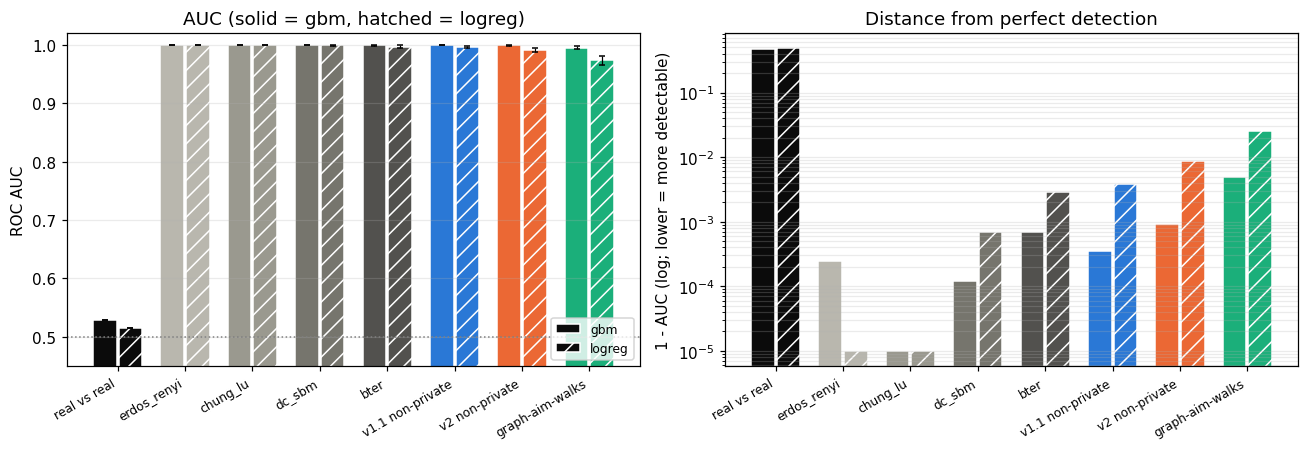

n_seeds  auc_mean  auc_std  auc_lo_mean  auc_hi_mean  \
label            model                                                          
real vs real     logreg        1    0.5147      NaN          NaN          NaN   
                 gbm           1    0.5285      NaN          NaN          NaN   
erdos_renyi      logreg        3    1.0000   0.0000       1.0000       1.0000   
                 gbm           3    0.9998   0.0004       0.9992       1.0000   
chung_lu         logreg        3    1.0000   0.0000       1.0000       1.0000   
                 gbm           3    1.0000   0.0000       1.0000       1.0000   
dc_sbm           logreg        3    0.9993   0.0004       0.9986       0.9998   
                 gbm           3    0.9999   0.0001       0.9997       1.0000   
bter             logreg        3    0.9971   0.0019       0.9946       0.9990   
                 gbm           3    0.9993   0.0010       0.9985       0.9999   
v1.1 non-private logreg        3    0.9962   0.0013       0.9938       0.9981   
                 gbm           3    0.9996   0.0004       0.9993       0.9999   
v2 non-private   logreg        3    0.9912   0.0005       0.9872       0.9947   
                 gbm           3    0.9991   0.0003       0.9983       0.9996   
graph-aim-walks  logreg        3    0.9743   0.0034       0.9660       0.9817   
                 gbm           3    0.9950   0.0003       0.9923       0.9974   

                         permuted_auc_mean         source  
label            model                                     
real vs real     logreg                NaN     results_v2  
                 gbm                   NaN     results_v2  
erdos_renyi      logreg             0.4300     results_v2  
                 gbm                0.4893     results_v2  
chung_lu         logreg             0.4242     results_v2  
                 gbm                0.4622     results_v2  
dc_sbm           logreg             0.4460     results_v2  
                 gbm                0.4784     results_v2  
bter             logreg             0.4764     results_v2  
                 gbm                0.4989     results_v2  
v1.1 non-private logreg             0.4630   results_v1_1  
                 gbm                0.4819   results_v1_1  
v2 non-private   logreg             0.3999     results_v2  
                 gbm                0.4981     results_v2  
graph-aim-walks  logreg             0.4252  results_walks  
                 gbm                0.4520  results_walks

In [2]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(len(LABELS))
w = 0.38
for j, (m, hatch) in enumerate(zip(MODELS, ("", "//"))):
    d = summary[summary["model"] == m].set_index("label").reindex(LABELS)
    lo = (d["auc_mean"] - d["auc_lo_mean"]).fillna(0).clip(lower=0)
    hi = (d["auc_hi_mean"] - d["auc_mean"]).fillna(0).clip(lower=0)
    cols = [COLOUR[l] for l in LABELS]
    ax.bar(x + (j - 0.5) * w, d["auc_mean"], width=w * 0.92, color=cols, hatch=hatch, edgecolor="white",
           yerr=[lo, hi], error_kw=dict(lw=0.8, capsize=2), label=m)
    bx.bar(x + (j - 0.5) * w, (1 - d["auc_mean"]).clip(lower=1e-5), width=w * 0.92, color=cols, hatch=hatch,
           edgecolor="white", label=m)
for p in (ax, bx):
    p.set_xticks(x, LABELS, rotation=30, ha="right", fontsize=8)
    p.grid(alpha=0.25, axis="y", which="both")
ax.axhline(0.5, color="gray", ls=":", lw=1)
ax.set(ylim=(0.45, 1.02), ylabel="ROC AUC", title="AUC (solid = gbm, hatched = logreg)")
bx.set(yscale="log", ylabel="1 - AUC (log; lower = more detectable)", title="Distance from perfect detection")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
show(fig)

cols = ["label", "model", "n_seeds", "auc_mean", "auc_std", "auc_lo_mean", "auc_hi_mean", "permuted_auc_mean", "source"]
display(summary[[c for c in cols if c in summary.columns]].set_index(["label", "model"]).round(4))

**What we see.** graph-aim-walks is the least detectable generator so far: gbm AUC 0.995 (v2 non-private 0.9991, v1.1 0.9996) and logreg 0.974 (v2 0.991). It is the first generator in this project below both structure baselines (BTER 0.9993, DC-SBM 0.9999) on the gbm, i.e. 5x further from perfect detection than v2 (right panel, log scale). It is still very far from the real-vs-real floor (0.53): a classifier separates its walks from real ones almost always.

## 2. What the classifier reads: feature-group importance by method

Permutation importance (AUC drop when one feature group is shuffled; fold 0, the method's strongest model) for the
groups of `graph_aim.eval.discriminator.GraphFeaturizer`: **attributes** (value shares and attribute statistics
inside the walk), **degree**, **structure** (density, clustering, ...), **size**. Log axis; drops within noise of zero
are clipped to 1e-5. *Look for:* the plan's acceptance asks both attributes and structure to fall against v2.

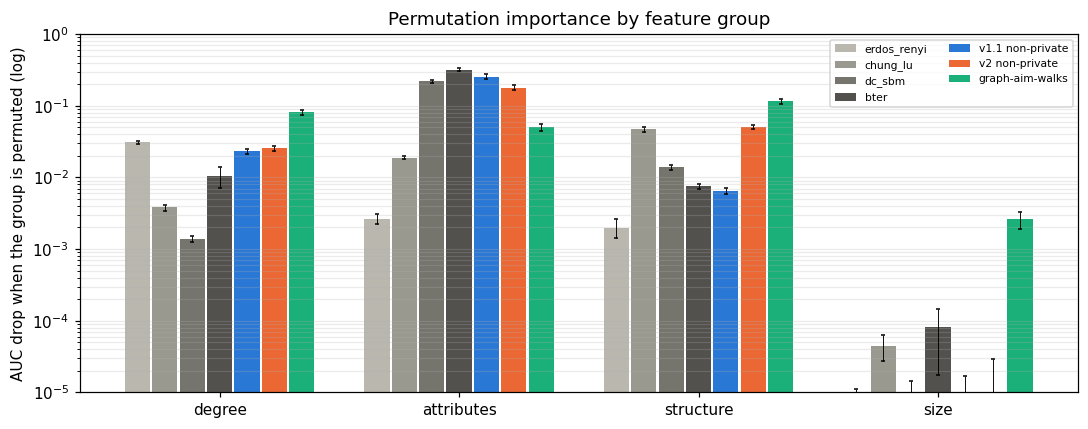

label,erdos_renyi,chung_lu,dc_sbm,bter,v1.1 non-private,v2 non-private,graph-aim-walks
group,,,,,,,
degree,0.0310,0.0038,0.0014,0.0105,0.0232,0.0257,0.0814
attributes,0.0026,0.0188,0.2190,0.3200,0.2554,0.1799,0.0501
structure,0.0020,0.0467,0.0138,0.0075,0.0065,0.0508,0.1161
size,0.0000,0.0000,0.0000,0.0001,0.0000,-0.0000,0.0026


In [3]:
FLOOR = 1e-5
if len(importance):
    groups = list(dict.fromkeys(importance["group"]))
    labs = [l for l in LABELS if l in set(importance["label"])]
    fig, ax = plt.subplots(figsize=(10, 4))
    w = 0.8 / len(labs)
    for j, l in enumerate(labs):
        d = importance[importance["label"] == l].set_index("group").reindex(groups)
        ax.bar(np.arange(len(groups)) + (j - (len(labs) - 1) / 2) * w, d["auc_drop"].clip(lower=FLOOR), width=w * 0.92,
               color=COLOUR[l], label=l, yerr=d["auc_drop_std"].fillna(0), error_kw=dict(lw=0.6, capsize=1.5))
    ax.set_xticks(range(len(groups)), groups)
    ax.set(yscale="log", ylim=(FLOOR, 1), ylabel="AUC drop when the group is permuted (log)",
           title="Permutation importance by feature group")
    ax.legend(fontsize=7, ncol=2, loc="upper right")
    ax.grid(alpha=0.25, axis="y", which="both")
    fig.tight_layout()
    show(fig)
    display(importance.pivot_table(index="group", columns="label", values="auc_drop", sort=False)[labs].round(4))
else:
    print("no importance tables found")

**What we see.** The classifier has changed what it looks at. For every earlier generator the attributes group dominated (v2: 0.18, v1.1: 0.26); for graph-aim-walks attributes fall to 0.05 and **structure (0.12) and degree (0.08) are now the giveaways** - consistent with the comparison notebook: clustering lost, degree mixing still too diagonal, regions too leaky. This is what the walk tables were meant to do for composition, and it moves the binding gap to structure.

## 3. AUC by walk size

AUC of the strongest model (fold 0) per bucket of walk size (number of distinct nodes in the sample), as 1 - AUC on
a log axis. The generator matched windows of up to 32 walk steps, so the larger buckets are further from what it
saw. *Look for:* does graph-aim-walks gain most on small walks and lose it on large ones?

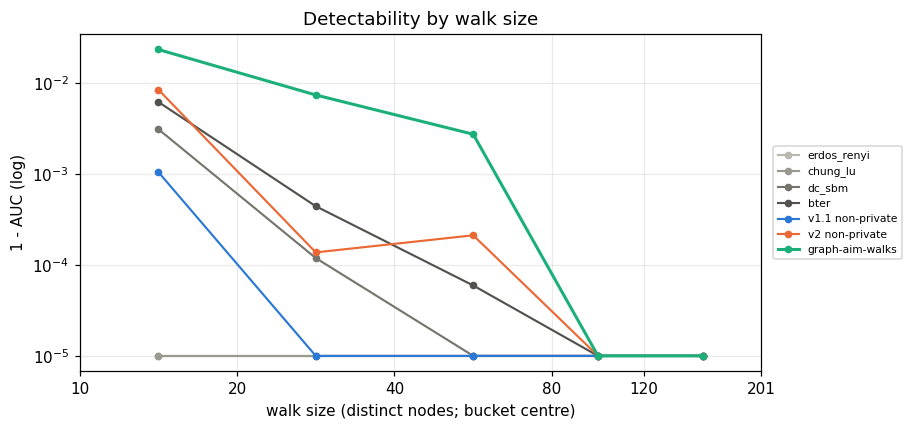

,label,erdos_renyi,chung_lu,dc_sbm,bter,v1.1 non-private,v2 non-private,graph-aim-walks
lo,hi,,,,,,,
10.0,20.0,1.0,1.0,0.9969,0.9938,0.9989,0.9915,0.9766
20.0,40.0,1.0,1.0,0.9999,0.9996,1.0000,0.9999,0.9926
40.0,80.0,1.0,1.0,1.0000,0.9999,1.0000,0.9998,0.9973
80.0,120.0,1.0,1.0,1.0000,1.0000,1.0000,1.0000,1.0000
120.0,201.0,1.0,1.0,1.0000,1.0000,1.0000,1.0000,1.0000


In [4]:
if len(by_size):
    fig, ax = plt.subplots(figsize=(8.4, 4))
    for l in [l for l in LABELS if l in set(by_size["label"])]:
        d = by_size[by_size["label"] == l].sort_values("lo")
        mid = np.sqrt(d["lo"] * d["hi"])
        ax.plot(mid, (1 - d["auc"]).clip(lower=1e-5), marker="o", ms=4, lw=2 if "walks" in l else 1.4,
                color=COLOUR[l], label=l)
    edges = sorted(set(by_size["lo"]) | set(by_size["hi"]))
    ax.set(xscale="log", yscale="log", xlabel="walk size (distinct nodes; bucket centre)",
           ylabel="1 - AUC (log)", title="Detectability by walk size")
    ax.set_xticks(edges, [str(int(e)) for e in edges])
    ax.minorticks_off()
    ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
    ax.grid(alpha=0.25, which="both")
    fig.tight_layout()
    show(fig)
    display(by_size.pivot_table(index=["lo", "hi"], columns="label", values="auc", sort=False).round(4))
else:
    print("no AUC-by-size tables found")

**What we see.** The improvement is concentrated in small walks: at 10-20 nodes 1-AUC rises from 0.008 (v2) to 0.023, at 20-40 nodes from 0.0001 to 0.007, at 40-80 from 0.0002 to 0.003. From 80 nodes up every generator, including this one, is detected perfectly. That is the held-out scale where the walk curves of the comparison notebook fall away from real: the generator matched statistics up to 32 steps and the classifier wins beyond them.

## 4. Inside the attributes group: subgroups

Present when the per-feature / subgroup importance diagnostics have been run (files
`discriminator_importance_subgroups*.csv` and `discriminator_importance_perfeature*.csv` in a results directory;
`viz_discriminator_v1_1.ipynb` explains them). The attributes group split by statistic type (`type:share`,
`type:none_other`, `type:same_edge_rate`, `type:pair_edge_match`) and by column (`share_col:<attribute>`); the
per-feature file gives the largest single-feature drop.

graph_aim_walks: attribute subgroups not yet generated (no discriminator_importance_subgroups*.csv in results_walks/)


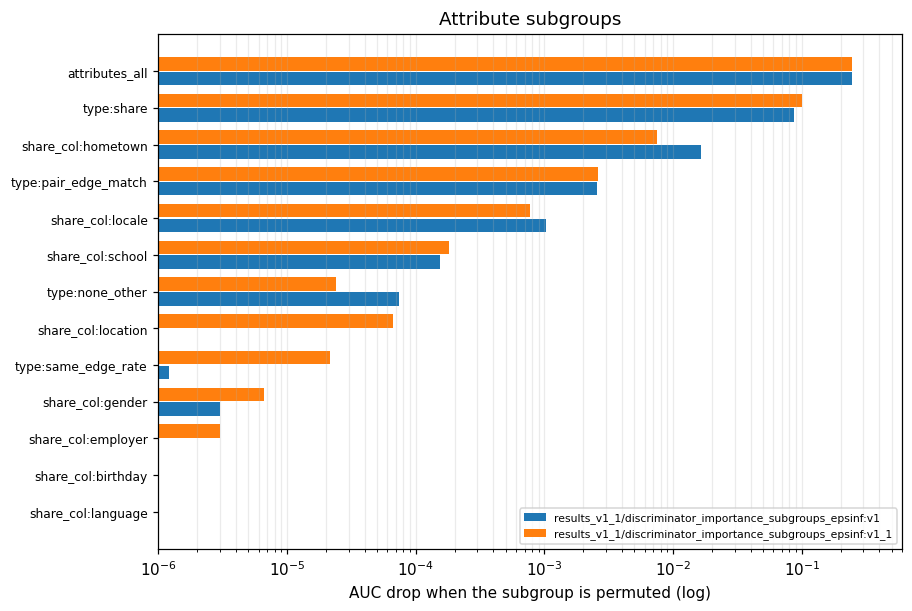

results_v1_1/discriminator_importance_perfeature_epsinf.csv: largest single attribute-feature drop v1 0.0012, v1_1 0.0005


In [5]:
sub_files = sorted(p for d in (R_WALKS, R_V2, R_V11) if d.exists() for p in d.glob("discriminator_importance_subgroups*.csv"))
if not any(p.parent == R_WALKS for p in sub_files):
    print("graph_aim_walks: attribute subgroups not yet generated (no discriminator_importance_subgroups*.csv in "
          "results_walks/)")
if sub_files:
    sub = pd.concat([pd.read_csv(p).assign(file=f"{p.parent.name}/{p.stem}") for p in sub_files], ignore_index=True)
    key = "version" if "version" in sub.columns else ("method" if "method" in sub.columns else "file")
    sub["series"] = sub["file"] + ":" + sub[key].astype(str) if key != "file" else sub["file"]
    order = sub.groupby("group")["auc_drop"].max().sort_values().index.tolist()
    series = list(dict.fromkeys(sub["series"]))
    fig, ax = plt.subplots(figsize=(8.4, 0.32 * len(order) * max(len(series), 2) / 2 + 1.5))
    h = 0.8 / len(series)
    for j, s in enumerate(series):
        d = sub[sub["series"] == s].set_index("group").reindex(order)
        ax.barh(np.arange(len(order)) + (j - (len(series) - 1) / 2) * h, d["auc_drop"].clip(lower=1e-6), height=h * 0.92,
                label=s)
    ax.set_yticks(range(len(order)), order, fontsize=8)
    ax.set(xscale="log", xlim=(1e-6, 0.6), xlabel="AUC drop when the subgroup is permuted (log)",
           title="Attribute subgroups")
    ax.legend(fontsize=7, loc="lower right")
    ax.grid(alpha=0.25, axis="x", which="both")
    fig.tight_layout()
    show(fig)
else:
    print("no subgroup importance files found")

for p in sorted(p for d in (R_WALKS, R_V2, R_V11) if d.exists() for p in d.glob("discriminator_importance_perfeature*.csv")):
    pf = pd.read_csv(p)
    attr = pf[pf["group"].str.startswith("attributes:")]
    by = "version" if "version" in pf.columns else None
    tops = attr.groupby(by)["auc_drop"].max() if by else pd.Series({"all": attr["auc_drop"].max()})
    print(f"{p.parent.name}/{p.name}: largest single attribute-feature drop " +
          ", ".join(f"{k} {v:.4f}" for k, v in tops.items()))

**What we see.** Per-attribute subgroup importances were not computed for the walks run (the subgroup split is a separate diagnostic run of the v1.1 round); the group-level drop of attributes to 0.05 in section 2 already shows the attribute signal is no longer the main one.

## Caveats

- The references come from earlier runs (`results_v2/`, `results_v1_1/`) of the same pipeline, sampler, featurizer
  and real graph; the real-vs-real control is the same graph's, so the numbers are comparable, but the folds differ.
- Importance and AUC by size are one fold (fold 0) of the method's strongest model.
- With the AUC saturated near 1, differences between methods are read on the log panels and in the importances.
- Every series here is non-private except the structure baselines' inputs (fitted to the real graph); this is a
  fidelity test, not a privacy test.